# Mô hình ARIMA(0, 1, 0) - Bước Đi Ngẫu Nhiên (Random Walk) Dự Báo Giá Cổ Phiếu Apple (AAPL)

- **Mục tiêu:** Xác định bộ tham số $(p, d, q)$ hoàn toàn dựa trên **kiểm định tính dừng ADF**, đồ thị **ACF (Autocorrelation Function)** và **PACF (Partial Autocorrelation Function)** theo phương pháp Box-Jenkins cổ điển (không dùng `auto_arima`).
- **Lý thuyết tài chính:** Mô hình $\text{ARIMA}(0, 1, 0)$ tương ứng với **Mô hình Bước đi ngẫu nhiên (Random Walk Model)** kinh điển trong lý thuyết tài chính (Giả thuyết Thị trường Hiệu quả - EMH), trong đó giá ngày mai được dự báo tốt nhất bằng giá ngày hôm nay cộng thêm nhiễu trắng:
  $$Price_{t+1} - Price_t = c + \epsilon_t \iff Price_{t+1} = Price_t + c + \epsilon_t$$
  (trong đó $c$ là **drift** - mức thay đổi trung bình mỗi phiên, được ước lượng từ dữ liệu; nếu $c = 0$ thì là random walk thuần).
- **Quy ước nhóm:** Phân chia tập dữ liệu 80% Full Train (trong đó 90% Fit, 10% Validation) và 20% Test theo đúng trình tự thời gian.
- **Kết quả xuất bản:** Xuất duy nhất 1 file kết quả dự báo trên toàn bộ dataset vào thư mục `model_predict/pred_ARIMA.csv`.


## 1. Khai báo các thư viện cần thiết

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


## 2. Đọc dữ liệu từ GitHub
Tải tập dữ liệu đã làm sạch `Apple_Stock_ready.csv` từ GitHub của nhóm, sắp xếp ngày giao dịch theo thứ tự tăng dần.


In [2]:
url = "https://raw.githubusercontent.com/nguyenkhachuy2006-eng/is403/main/Cleaned%20data/Apple_Stock_ready.csv"
df = pd.read_csv(url, parse_dates=["Date"])
df = df.sort_values("Date").reset_index(drop=True)

print("=== THÔNG TIN DỮ LIỆU ===")
print("Tổng số dòng:", len(df))
print("Khoảng thời gian:", df["Date"].min().strftime('%Y-%m-%d'), "đến", df["Date"].max().strftime('%Y-%m-%d'))
df.head()


=== THÔNG TIN DỮ LIỆU ===
Tổng số dòng: 4020
Khoảng thời gian: 2010-10-04 đến 2026-09-28


,Date,Year,Month,Day,DayOfWeek,Price,Open,High,Low,Volume,Change_Pct,Return_1,High_Low_Range,Open_Close_Change,NextPrice
0,2010-10-04,2010,10,4,0,9.95,10.06,10.10,9.92,435300000.0,-0.0137,-0.013875,0.18,-0.11,10.32
1,2010-10-05,2010,10,5,1,10.32,10.07,10.34,10.07,501970000.0,0.0370,0.037186,0.27,0.25,10.33
2,2010-10-06,2010,10,6,2,10.33,10.34,10.43,10.19,670870000.0,0.0009,0.000969,0.24,-0.01,10.33
3,2010-10-07,2010,10,7,3,10.33,10.37,10.37,10.25,408400000.0,0.0000,0.000000,0.12,-0.04,10.50
4,2010-10-08,2010,10,8,4,10.50,10.42,10.52,10.36,658400000.0,0.0168,0.016457,0.16,0.08,10.55


## 3. Phân chia Train / Validation / Test theo thứ tự thời gian
- Tỷ lệ 80% cho Full Train và 20% cho Test.
- Trong tập Full Train, tách 90% đầu tiên cho `train_fit` (2,894 dòng) và 10% sau cho `train_val` (322 dòng).
- Toàn bộ quá trình kiểm định dừng, vẽ ACF/PACF và xác định tham số $(p, d, q)$ **chỉ được thực hiện trên tập `train_fit`** để đảm bảo không bị rò rỉ thông tin (data leakage).


In [3]:
n = len(df)
i_train = int(n * 0.80)
train = df.iloc[:i_train].copy()
test  = df.iloc[i_train:].copy()

i_val = int(len(train) * 0.90)
train_fit = train.iloc[:i_val].copy()
train_val = train.iloc[i_val:].copy()

print("=== PHÂN CHIA DỮ LIỆU ===")
print(f"train_fit:  {len(train_fit)} dòng ({len(train_fit)/n*100:.1f}%)")
print(f"train_val:  {len(train_val)} dòng ({len(train_val)/n*100:.1f}%)")
print(f"test:       {len(test)} dòng ({len(test)/n*100:.1f}%)")


=== PHÂN CHIA DỮ LIỆU ===
train_fit:  2894 dòng (72.0%)
train_val:  322 dòng (8.0%)
test:       804 dòng (20.0%)


## 4. Xác định bậc sai phân $d$ qua Kiểm định tính dừng (ADF Test)
- Sử dụng kiểm định **Augmented Dickey-Fuller (ADF)** trên tập `train_fit`.
- **Giả thuyết $H_0$:** Chuỗi có nghiệm đơn vị (Non-stationary - Không dừng).
- **Giả thuyết $H_1$:** Chuỗi dừng (Stationary).
- Nếu $p\text{-value} > 0.05$: Không bác bỏ $H_0$, chuỗi không dừng $\rightarrow$ Tiếp tục lấy sai phân bậc kế tiếp.
- Lặp lại quá trình sai phân cho đến khi $p\text{-value} < 0.05$ thì dừng lại để xác định bậc sai phân $d$.


In [4]:
def check_stationarity(series, name="Chuỗi dữ liệu"):
    result = adfuller(series.dropna())
    adf_stat, p_value, lags, nobs, crit_vals, icbest = result
    print(f"--- Kiểm định ADF: {name} ---")
    print(f"  ADF Statistic : {adf_stat:.6f}")
    print(f"  p-value       : {p_value:.6e}")
    print(f"  Critical Value (5%): {crit_vals['5%']:.4f}")
    if p_value < 0.05:
        print(f"  => KẾT LUẬN: Chuỗi ĐÃ DỪNG (Stationary) ở mức ý nghĩa 5%.\n")
        return True
    else:
        print(f"  => KẾT LUẬN: Chuỗi KHÔNG DỪNG (Non-Stationary). Cần thực hiện sai phân!\n")
        return False

# 1. Kiểm tra chuỗi gốc Price
price_series = train_fit["Price"]
is_stat = check_stationarity(price_series, "Giá cổ phiếu gốc (Price)")

# 2. Vòng lặp sai phân cho đến khi chuỗi dừng
d = 0
diff_series = price_series.copy()
while not is_stat:
    d += 1
    diff_series = diff_series.diff().dropna()
    is_stat = check_stationarity(diff_series, f"Chuỗi sau sai phân bậc {d} (diff_{d})")

print(f"===> KẾT QUẢ XÁC ĐỊNH BẬC SAI PHÂN: d = {d}")


--- Kiểm định ADF: Giá cổ phiếu gốc (Price) ---
  ADF Statistic : 2.579164
  p-value       : 9.990710e-01
  Critical Value (5%): -2.8625
  => KẾT LUẬN: Chuỗi KHÔNG DỪNG (Non-Stationary). Cần thực hiện sai phân!

--- Kiểm định ADF: Chuỗi sau sai phân bậc 1 (diff_1) ---
  ADF Statistic : -10.702491
  p-value       : 3.494415e-19
  Critical Value (5%): -2.8625
  => KẾT LUẬN: Chuỗi ĐÃ DỪNG (Stationary) ở mức ý nghĩa 5%.

===> KẾT QUẢ XÁC ĐỊNH BẬC SAI PHÂN: d = 1


## 5. Trực quan hóa Chuỗi gốc và Chuỗi sau sai phân bậc $d=1$

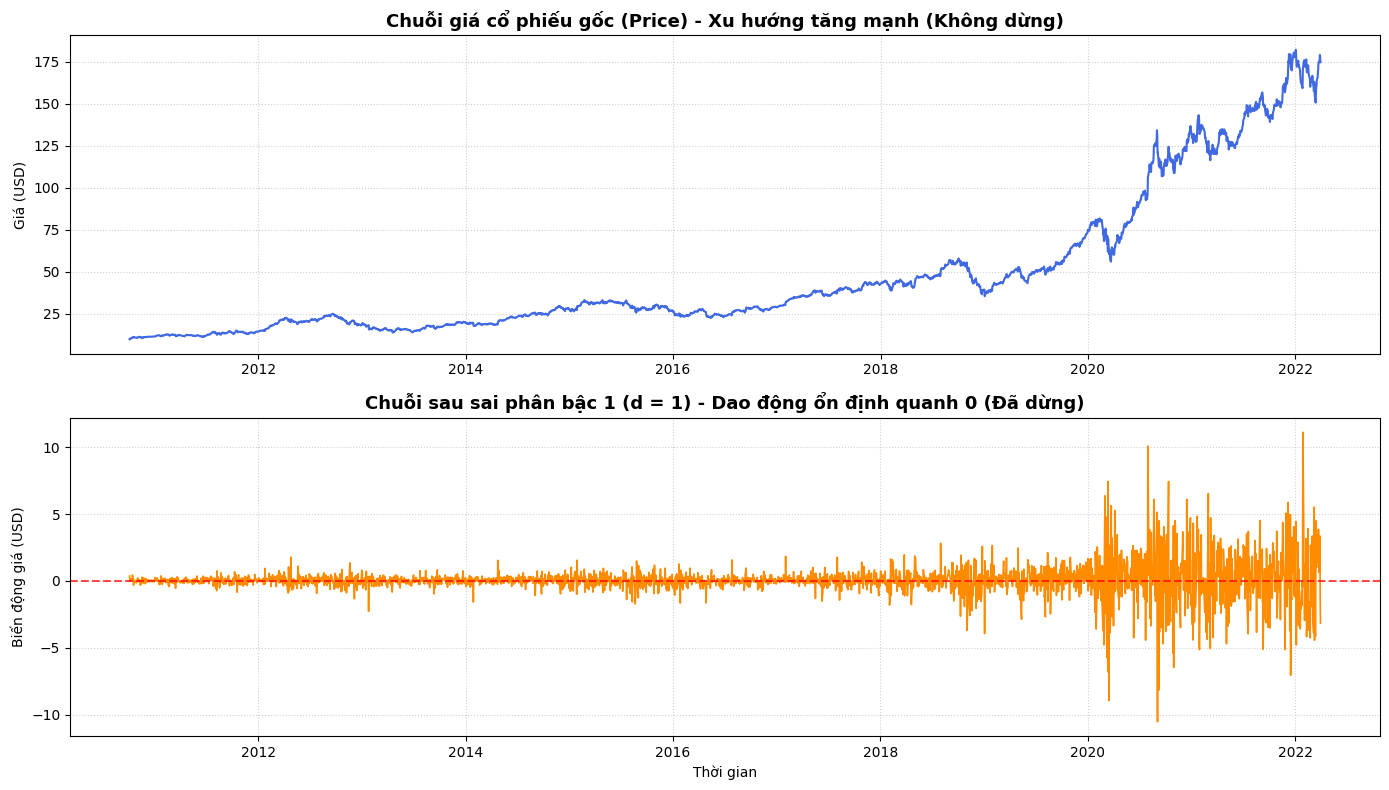

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

# Chuỗi gốc
axes[0].plot(train_fit["Date"], train_fit["Price"], color="royalblue", linewidth=1.5)
axes[0].set_title("Chuỗi giá cổ phiếu gốc (Price) - Xu hướng tăng mạnh (Không dừng)", fontsize=13, fontweight='bold')
axes[0].set_ylabel("Giá (USD)")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Chuỗi sai phân bậc 1
diff_val = train_fit["Price"].diff().dropna()
axes[1].plot(train_fit["Date"].iloc[1:], diff_val, color="darkorange", linewidth=1.2)
axes[1].axhline(0, color="red", linestyle="--", alpha=0.7)
axes[1].set_title(f"Chuỗi sau sai phân bậc {d} (d = {d}) - Dao động ổn định quanh 0 (Đã dừng)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Thời gian")
axes[1].set_ylabel("Biến động giá (USD)")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 6. Phân tích đồ thị ACF và PACF để xác định $p$ và $q$ theo Box-Jenkins

**Quy tắc nhận dạng theo phương pháp Box-Jenkins (tìm điểm cắt - cut-off):**
1. **AR(p):** đồ thị **PACF cắt đột ngột sau lag $p$** (các lag sau đó nằm trong dải tin cậy), còn ACF giảm dần.
2. **MA(q):** đồ thị **ACF cắt đột ngột sau lag $q$**, còn PACF giảm dần.
3. **Không có điểm cắt rõ ràng:** nếu các hệ số ACF/PACF đều rất nhỏ và không dừng lại (cắt) ở lag nào, thì không thể nhận dạng cấu trúc AR/MA từ đồ thị; khi đó chọn mô hình đơn giản nhất $\rightarrow$ $p = q = 0$.

**Lưu ý:** dải tin cậy 95% ($\pm 1.96/\sqrt{N}$) nghĩa là trung bình khoảng 5% số lag (khoảng 2 trên 40 lag) sẽ vượt ngưỡng chỉ do ngẫu nhiên. Vì vậy không chọn $p$, $q$ bằng "lag cuối cùng vượt ngưỡng".

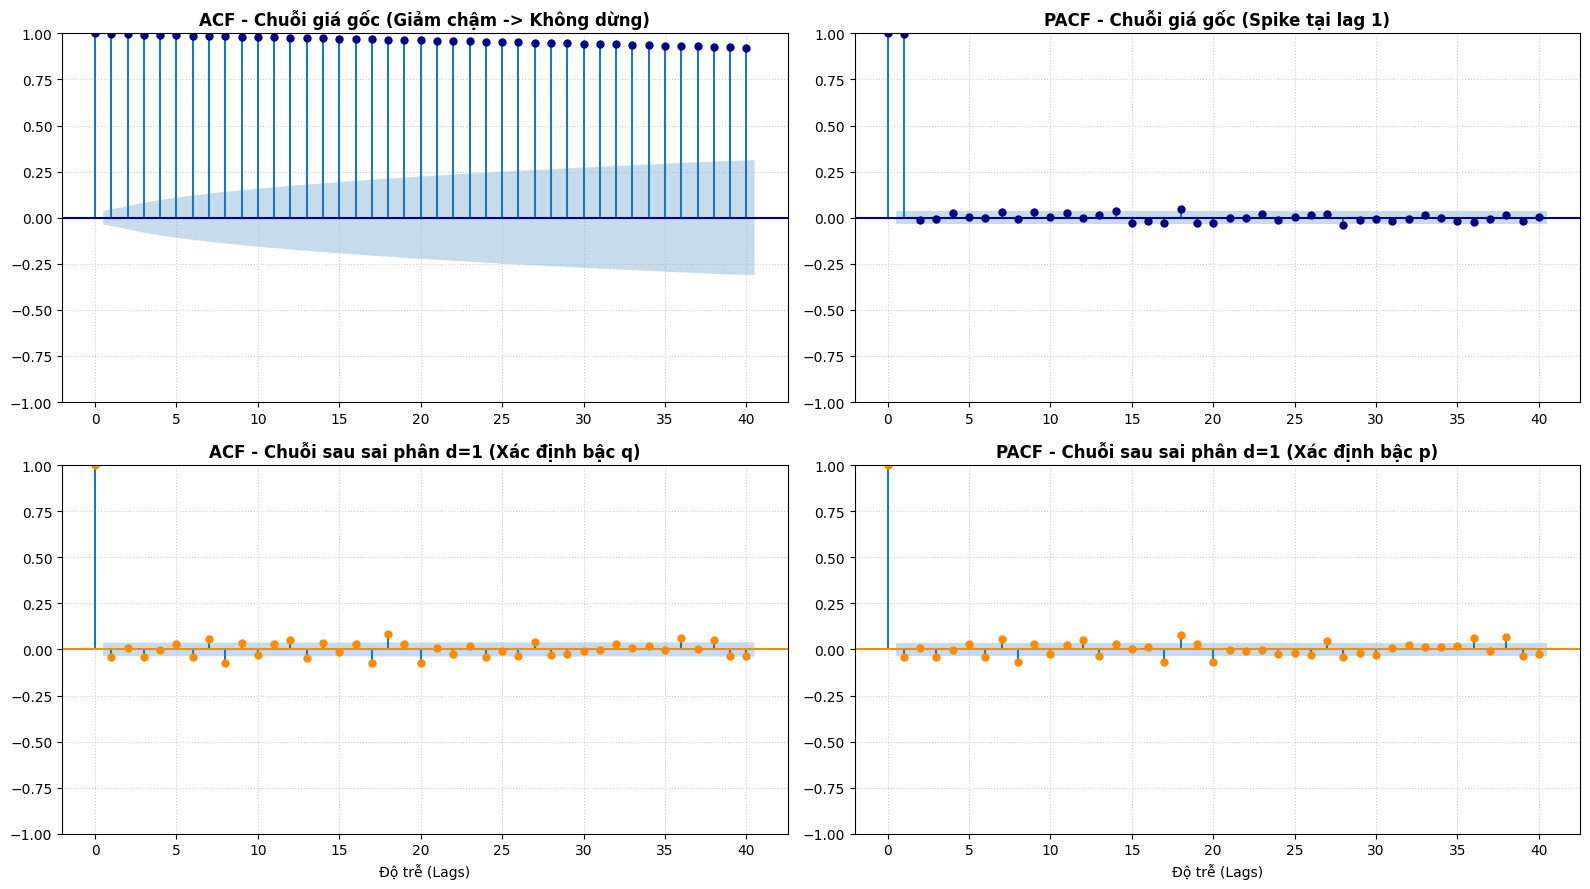

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))

# ACF & PACF chuỗi gốc
plot_acf(train_fit["Price"], ax=axes[0, 0], lags=40, color="navy")
axes[0, 0].set_title("ACF - Chuỗi giá gốc (Giảm chậm -> Không dừng)", fontsize=12, fontweight='bold')
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

plot_pacf(train_fit["Price"], ax=axes[0, 1], lags=40, color="navy", method="ywm")
axes[0, 1].set_title("PACF - Chuỗi giá gốc (Spike tại lag 1)", fontsize=12, fontweight='bold')
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

# ACF & PACF chuỗi sau sai phân bậc 1
plot_acf(diff_val, ax=axes[1, 0], lags=40, color="darkorange")
axes[1, 0].set_title(f"ACF - Chuỗi sau sai phân d={d} (Xác định bậc q)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("Độ trễ (Lags)")
axes[1, 0].grid(True, linestyle=":", alpha=0.6)

plot_pacf(diff_val, ax=axes[1, 1], lags=40, color="darkorange", method="ywm")
axes[1, 1].set_title(f"PACF - Chuỗi sau sai phân d={d} (Xác định bậc p)", fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel("Độ trễ (Lags)")
axes[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 7. Lựa chọn Mô hình $\text{ARIMA}(0, 1, 0)$ dựa trên Phân tích ACF/PACF

**Kết luận:** tự tương quan của chuỗi sai phân rất yếu và không có cấu trúc rõ ràng, nên chọn mô hình đơn giản nhất $p = 0$, $d = 1$, $q = 0$, tức là **Random Walk có drift**. (Hạn chế: kiểm định Ljung-Box ở cuối notebook vẫn phát hiện tự tương quan yếu còn sót lại, xem phần thảo luận ở đó.)

### Triển khai công thức ARIMA(0,1,0)

**Bước 1: Công thức tổng quát**

$$
\Delta^d y_t =
\mu+\phi_0+
\sum_{i=1}^{p}\phi_i\Delta^d y_{t-i}
+\sum_{j=1}^{q}\theta_j\epsilon_{t-j}
+\epsilon_t
$$

**Bước 2: Xác định tham số**

$$
p=0,\quad d=1,\quad q=0
$$

**Bước 3: Thay tham số vào công thức**

$$
\Delta y_t =
\mu+\phi_0+
\sum_{i=1}^{0}\phi_i\Delta y_{t-i}
+\sum_{j=1}^{0}\theta_j\epsilon_{t-j}
+\epsilon_t
$$

Vì p = 0 và q = 0, hai thành phần tổng bị loại bỏ:

$$
\Delta y_t=\mu+\phi_0+\epsilon_t
$$

**Bước 4: Khai triển sai phân bậc 1**

Theo định nghĩa:

$$
\Delta y_t=y_t-y_{t-1}
$$

Thay vào phương trình:

$$
y_t-y_{t-1}=\mu+\phi_0+\epsilon_t
$$

Chuyển vế:

$$
\boxed{y_t=y_{t-1}+\mu+\phi_0+\epsilon_t}
$$

**Kết luận:**

Đặt c = μ + φ₀, ta có:

$$
\boxed{y_t=y_{t-1}+c+\epsilon_t}
$$

Đây là mô hình Random Walk có drift. Nếu c = 0, mô hình trở thành Random Walk không có drift.

**Ghi chú về hằng số:** $\mu$ và $\phi_0$ đều là số hạng hằng số nên trùng vai trò, không thể ước lượng riêng rẽ. Trong thực hành chỉ ước lượng **một** hằng số $c = \mu + \phi_0$ (drift), tương ứng `trend='t'` trong `statsmodels` khi $d = 1$. Giá trị $c$ do thuật toán ước lượng (xấp xỉ trung bình của chuỗi sai phân), và dự báo là $\hat{y}_{T+1} = y_T + c$.

## 8. Huấn luyện và Dự báo Rolling Forecast trên tập Validation với $\text{ARIMA}(0, 1, 0)$
Áp dụng chiến lược **One-step-ahead Walk-Forward Validation**: cập nhật giá trị thực tế sau mỗi bước (`refit=False`) để dự báo ngày kế tiếp một cách liên tục và bảo đảm tính trung thực về mặt thời gian.


In [9]:

def rolling_forecast(y_init, eval_series, order):
    # Thực hiện rolling forecast 1-bước-tới bằng ARIMA
    res = ARIMA(y_init, order=order, trend=TREND).fit()
    preds = []
    for price_t in eval_series:
        res = res.append([price_t], refit=False)
        preds.append(float(res.forecast(1)[0])) 
    print("Tên tham số:", res.param_names)
    print("Giá trị tham số:", res.params)    
    return np.array(preds)

order = (0, 1, 0);  # p, d, q
TREND = "t"
print(f"Đang chạy rolling forecast trên tập Validation với mô hình ARIMA{order}...")
pred_val = rolling_forecast(train_fit["Price"].values, train_val["Price"].values, order)
print(f"✓ Đã hoàn thành dự báo {len(pred_val)} phiên tập Validation.")



Đang chạy rolling forecast trên tập Validation với mô hình ARIMA(0, 1, 0)...
Tên tham số: ['x1', 'sigma2']
Giá trị tham số: [0.0569117  1.43318028]
✓ Đã hoàn thành dự báo 322 phiên tập Validation.


## 9. Dự báo Rolling Forecast trên tập Test với $\text{ARIMA}(0, 1, 0)$
Ghép toàn bộ dữ liệu lịch sử `train_fit + train_val` (80% Full Train) làm điểm khởi đầu để dự báo cho 804 phiên của tập Test.


In [ ]:
history = np.concatenate([train_fit["Price"].values, train_val["Price"].values])

print(f"Đang chạy rolling forecast trên tập Test (804 phiên) với mô hình ARIMA{order}...")
pred_test = rolling_forecast(history, test["Price"].values, order)
print(f"✓ Đã hoàn thành dự báo {len(pred_test)} phiên tập Test.")



Đang chạy rolling forecast trên tập Test (804 phiên) với mô hình ARIMA(0, 1, 0)...
✓ Đã hoàn thành dự báo 804 phiên tập Test.


## 10. Đánh giá mô hình $\text{ARIMA}(0, 1, 0)$ trên Validation và Test
Tính toán các chỉ số: MAE, RMSE, $R^2$, và Directional Accuracy (DirAcc %).


**Lưu ý khi đọc kết quả:**
- $R^2$ rất cao (0.99) chủ yếu vì giá hôm nay luôn rất gần giá ngày mai (tính trên mức giá, không phải trên mức thay đổi), không có nghĩa mô hình dự báo biến động giỏi.
- Vì drift $c > 0$ nên mô hình luôn dự báo "giá tăng nhẹ", do đó **DirAcc chỉ bằng tỷ lệ ngày giá thực sự tăng**, không phản ánh khả năng đoán hướng. Đây là hạn chế đã biết của mô hình random walk.

In [ ]:
def metrics(y_true, y_pred, price_t):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    
    dir_true = (y_true > price_t).astype(int)
    dir_pred = (y_pred > price_t).astype(int)
    diracc = np.mean(dir_true == dir_pred) * 100
    
    return mae, rmse, r2, diracc

val_mae, val_rmse, val_r2, val_diracc = metrics(
    train_val["NextPrice"].values, pred_val, train_val["Price"].values
)

test_mae, test_rmse, test_r2, test_diracc = metrics(
    test["NextPrice"].values, pred_test, test["Price"].values
)

print(f"=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ARIMA{order} ===")
print("TẬP VALIDATION:")
print(f"  MAE    : {val_mae:.4f} USD")
print(f"  RMSE   : {val_rmse:.4f} USD")
print(f"  R²     : {val_r2:.4f}")
print(f"  DirAcc : {val_diracc:.2f}%")

print("\nTẬP TEST:")
print(f"  MAE    : {test_mae:.4f} USD")
print(f"  RMSE   : {test_rmse:.4f} USD")
print(f"  R²     : {test_r2:.4f}")
print(f"  DirAcc : {test_diracc:.2f}%")


=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ARIMA(0, 1, 0) ===
TẬP VALIDATION:
  MAE    : 2.2684 USD
  RMSE   : 3.0069 USD
  R²     : 0.9626
  DirAcc : 51.24%

TẬP TEST:
  MAE    : 2.6194 USD
  RMSE   : 3.8419 USD
  R²     : 0.9923
  DirAcc : 53.98%


## 11. Xuất duy nhất 1 file CSV vào thư mục `model_predict`
- Tạo kết quả dự báo trên toàn bộ tập dữ liệu (4,020 dòng).
- Lưu **duy nhất 1 file CSV** vào thư mục `model_predict`:
  👉 `model_predict/pred_ARIMA.csv`


In [ ]:
# Xác định thư mục model_predict
predict_dir = os.path.join("..", "model_predict") if os.path.exists("..") and os.path.basename(os.getcwd()) == "model" else "model_predict"
os.makedirs(predict_dir, exist_ok=True)

# Dự báo 1-bước-tới trong mẫu cho train_fit.
# Quy ước thống nhất với val/test: dòng t chứa dự báo cho NextPrice của dòng t (tức giá ngày t+1, dựa trên thông tin đến ngày t).
# predict(start=1, end=len) trả về dự báo cho giá tại các chỉ số 1..len, nên phần tử thứ t là dự báo cho NextPrice của dòng t.
res_fit = ARIMA(train_fit["Price"].values, order=order, trend=TREND).fit()
pred_train_fit = np.asarray(res_fit.predict(start=1, end=len(train_fit)))

# Ghép kết quả toàn bộ dataset: train_fit + train_val + test
pred_all = np.concatenate([pred_train_fit, pred_val, pred_test])

pred_full_df = pd.DataFrame({
    "Date": df["Date"].values,
    "price_pred": pred_all
})

output_csv_path = os.path.join(predict_dir, "pred_ARIMA.csv")
pred_full_df.to_csv(output_csv_path, index=False)

print(f"✓ Đã lưu thành công 1 file duy nhất vào: {output_csv_path}")
print(f"  - Số dòng: {len(pred_full_df)} (khớp toàn bộ dataset {len(df)} dòng)")
print(f"  - Các cột: {list(pred_full_df.columns)}")


✓ Đã lưu thành công 1 file duy nhất vào: ..\model_predict\pred_ARIMA.csv
  - Số dòng: 4020 (khớp toàn bộ dataset 4020 dòng)
  - Các cột: ['Date', 'price_pred']


## 12. Trực quan hóa kết quả dự báo của mô hình $\text{ARIMA}(0, 1, 0)$

### Biểu đồ 1: Kết quả dự báo trên tập Validation

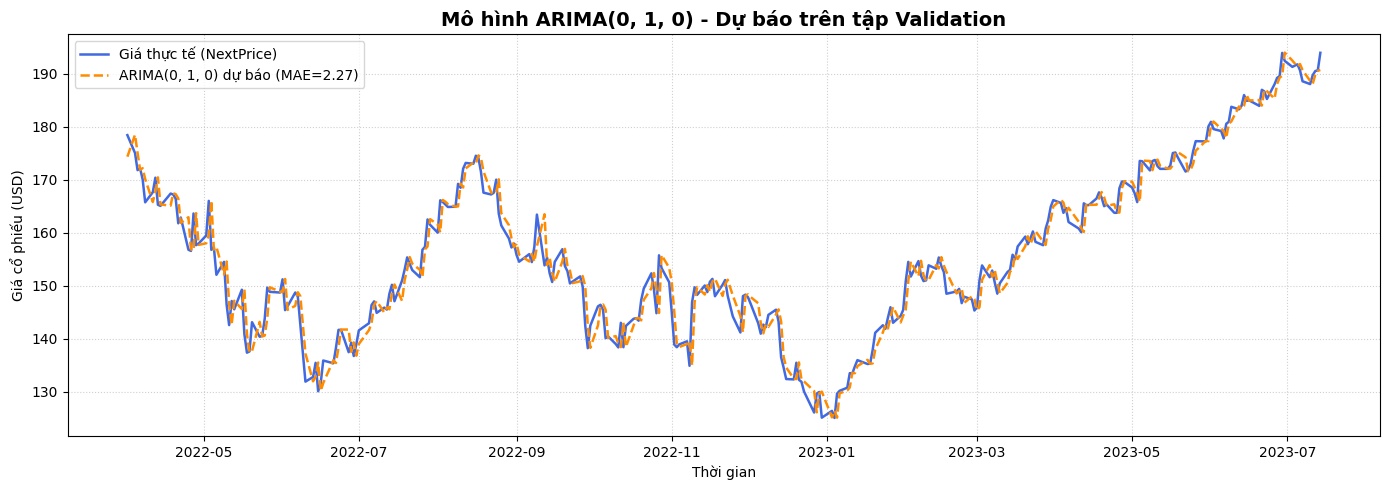

In [ ]:
plt.figure(figsize=(14, 5))
plt.plot(train_val["Date"], train_val["NextPrice"], label="Giá thực tế (NextPrice)", color="royalblue", linewidth=1.8)
plt.plot(train_val["Date"], pred_val, label=f"ARIMA{order} dự báo (MAE={val_mae:.2f})", color="darkorange", linestyle="--", linewidth=1.8)
plt.title(f"Mô hình ARIMA{order} - Dự báo trên tập Validation", fontsize=14, fontweight="bold")
plt.xlabel("Thời gian")
plt.ylabel("Giá cổ phiếu (USD)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


### Biểu đồ 2: Kết quả dự báo trên toàn bộ tập Test (804 phiên)

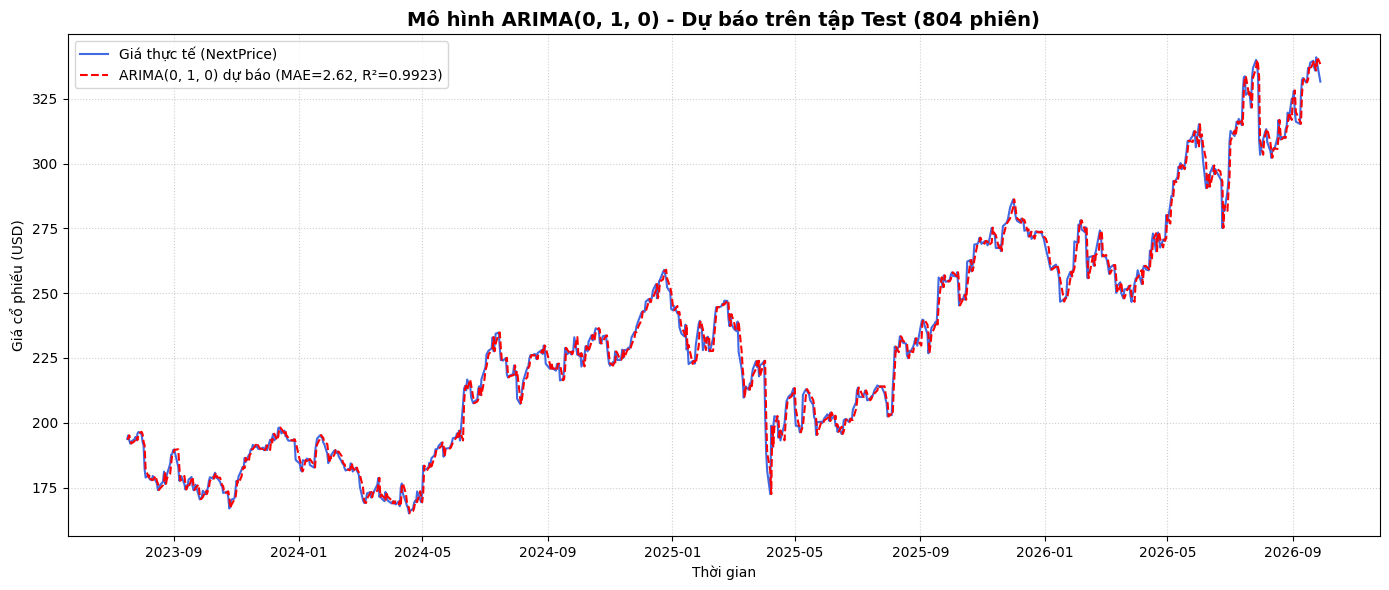

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(test["Date"], test["NextPrice"], label="Giá thực tế (NextPrice)", color="royalblue", linewidth=1.5)
plt.plot(test["Date"], pred_test, label=f"ARIMA{order} dự báo (MAE={test_mae:.2f}, R²={test_r2:.4f})", color="red", linestyle="--", linewidth=1.5)
plt.title(f"Mô hình ARIMA{order} - Dự báo trên tập Test (804 phiên)", fontsize=14, fontweight="bold")
plt.xlabel("Thời gian")
plt.ylabel("Giá cổ phiếu (USD)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


### Biểu đồ 3: So sánh chi tiết trong 100 phiên giao dịch cuối cùng của Test

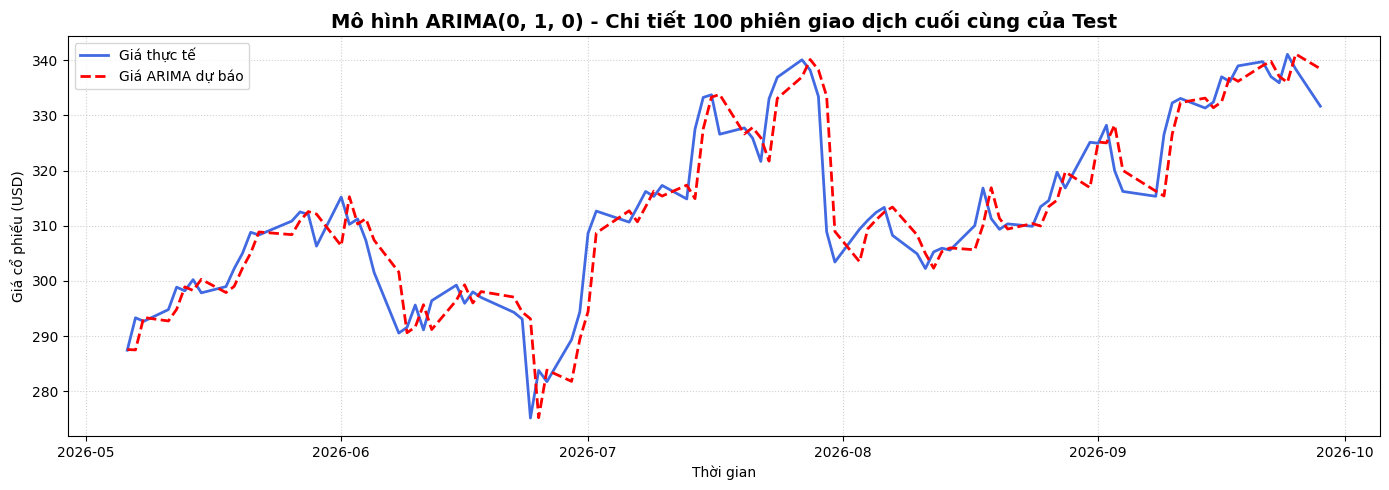

In [ ]:
last_n = min(100, len(test))
plt.figure(figsize=(14, 5))
plt.plot(test["Date"].iloc[-last_n:], test["NextPrice"].iloc[-last_n:], label="Giá thực tế", color="royalblue", linewidth=2)
plt.plot(test["Date"].iloc[-last_n:], pred_test[-last_n:], label="Giá ARIMA dự báo", color="red", linestyle="--", linewidth=2)
plt.title(f"Mô hình ARIMA{order} - Chi tiết 100 phiên giao dịch cuối cùng của Test", fontsize=14, fontweight="bold")
plt.xlabel("Thời gian")
plt.ylabel("Giá cổ phiếu (USD)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


### Biểu đồ 4: Sai số dự báo (Residuals) theo thời gian trên tập Test

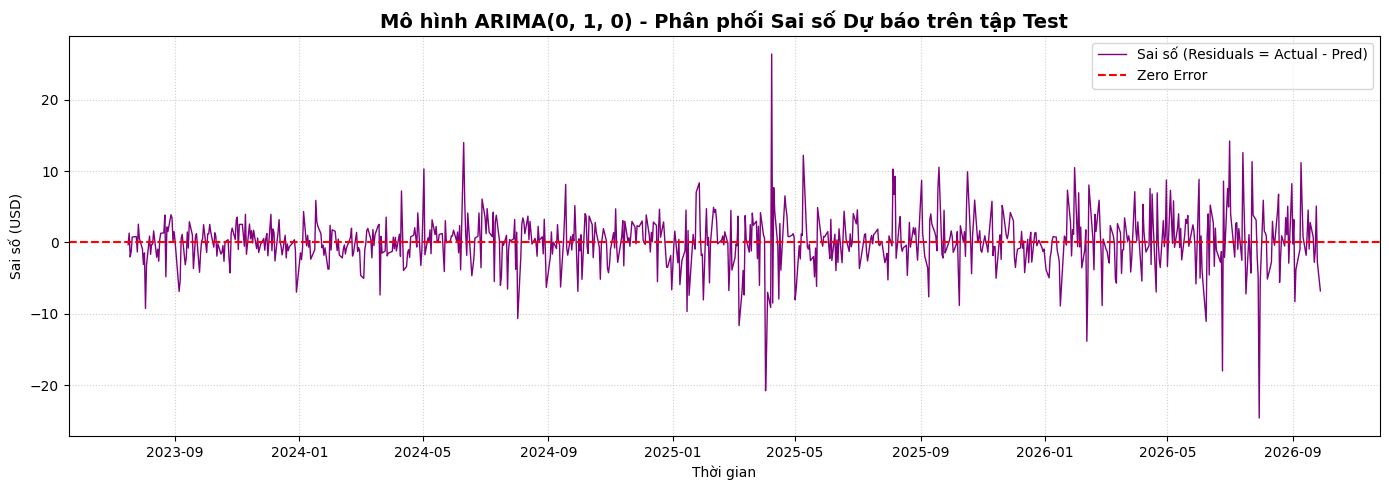

In [ ]:
residuals_test = test["NextPrice"].values - pred_test
plt.figure(figsize=(14, 5))
plt.plot(test["Date"], residuals_test, color="purple", linewidth=1, label="Sai số (Residuals = Actual - Pred)")
plt.axhline(0, color="red", linestyle="--", label="Zero Error")
plt.title(f"Mô hình ARIMA{order} - Phân phối Sai số Dự báo trên tập Test", fontsize=14, fontweight="bold")
plt.xlabel("Thời gian")
plt.ylabel("Sai số (USD)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


### Biểu đồ/Kiểm định 5: Kiểm tra residual của mô hình (Ljung-Box)
Kiểm tra residual trong mẫu của $\text{ARIMA}(0, 1, 0)$ có tự tương quan hay không ($H_0$: không tự tương quan, tức nhiễu trắng).

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

resid_fit = np.asarray(res_fit.resid)[1:]   # bỏ phần tử đầu (khởi tạo)
lb = acorr_ljungbox(resid_fit, lags=[5, 10, 20], return_df=True)
print(lb)
print(f"\nResidual: trung bình = {resid_fit.mean():.4f}, độ lệch chuẩn = {resid_fit.std():.4f}")
print(f"|ACF residual| lớn nhất (lag 1-20) = {np.abs(acf(resid_fit, nlags=20)[1:]).max():.4f}")

       lb_stat     lb_pvalue
5    12.890314  2.442861e-02
10   48.827341  4.380977e-07
20  127.157774  1.327773e-17

Residual: trung bình = 0.0000, độ lệch chuẩn = 1.1972
|ACF residual| lớn nhất (lag 1-20) = 0.0819
